# FEATURE SELECTION TRÊN BỘ DỮ LIỆU HOUSE PRICES

### Mục tiêu
- Chọn và tải bộ dữ liệu House Prices Prediction.
- Tiền xử lý dữ liệu số và dữ liệu phân loại.
- Khám phá dữ liệu (EDA) và kiểm tra dữ liệu thiếu.
- Xây dựng mô hình cơ sở với SVM, Random Forest và XGBoost.
- Áp dụng các kỹ thuật Feature Selection:
  1. SelectKBest - Filter Method.
  2. SelectFromModel với Random Forest - Embedded Method.
  3. RFE với Linear SVM - Wrapper Method.
- So sánh MAE, RMSE, R² và thời gian huấn luyện.
- Xác định phương pháp Feature Selection và mô hình phù hợp nhất.

## 1. Tổng quan bài toán

Bộ dữ liệu House Prices - Advanced Regression Techniques dùng để dự đoán giá bán nhà `SalePrice` dựa trên các đặc trưng về diện tích, chất lượng, vị trí, cấu trúc, năm xây dựng và nhiều thuộc tính khác.

## 2. Cài đặt thư viện

In [2]:
import sys
import subprocess

try:
    import xgboost
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])

## 3. Import các thư viện

In [3]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression, SelectFromModel, RFE
from sklearn.svm import SVR, LinearSVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

## 4. Thiết lập tham số chung

In [4]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Random state:", RANDOM_STATE)
print("Tỷ lệ tập kiểm tra:", TEST_SIZE)

Random state: 42
Tỷ lệ tập kiểm tra: 0.2


## 5. Đọc dữ liệu


In [6]:
possible_paths = [
    "/kaggle/input/datasets/nguynhongquy107/hhhhhhh/train.csv"
]

data_path = None
for p in possible_paths:
    if os.path.exists(p):
        data_path = p
        break


df = pd.read_csv(data_path)

print("Đường dẫn dữ liệu:", data_path)
print("Đọc dữ liệu thành công.")

Đường dẫn dữ liệu: /kaggle/input/datasets/nguynhongquy107/hhhhhhh/train.csv
Đọc dữ liệu thành công.


## 6. Xem 5 dòng đầu tiên

In [7]:
display(df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 7. Kích thước dữ liệu

In [8]:
print(f"Số dòng: {df.shape[0]}")
print(f"Số cột: {df.shape[1]}")

Số dòng: 1460
Số cột: 81


## 8. Thông tin kiểu dữ liệu

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## 9. Thống kê mô tả

In [ ]:
display(df.describe(include="all").T)

## 10. Kiểm tra dữ liệu trùng lặp

In [10]:
duplicate_count = df.duplicated().sum()
print("Số dòng trùng lặp:", duplicate_count)

Số dòng trùng lặp: 0


## 11. Kiểm tra giá trị thiếu

In [11]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percent": missing_pct
})

display(missing_table[missing_table["Missing_Count"] > 0].head(30))

,Missing_Count,Missing_Percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


## 12. Trực quan hóa các cột có nhiều giá trị thiếu

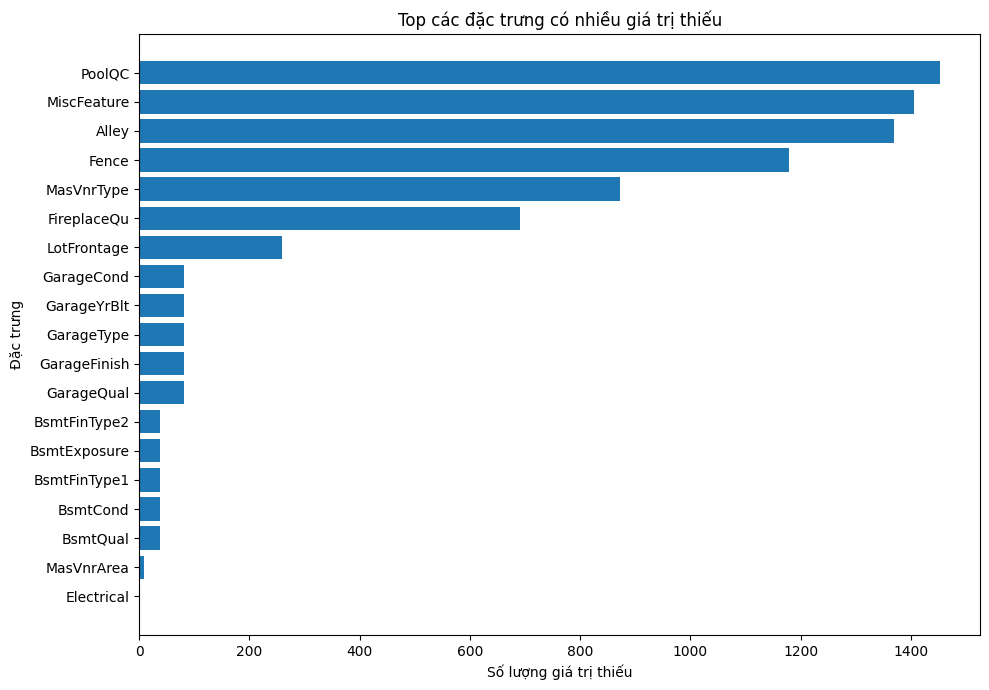

In [12]:
missing_top = missing[missing > 0].head(20).sort_values()

plt.figure(figsize=(10, 7))
plt.barh(missing_top.index, missing_top.values)
plt.xlabel("Số lượng giá trị thiếu")
plt.ylabel("Đặc trưng")
plt.title("Top các đặc trưng có nhiều giá trị thiếu")
plt.tight_layout()
plt.show()

## 13. Kiểm tra biến mục tiêu SalePrice

In [13]:
target = "SalePrice"

print("Min:", df[target].min())
print("Max:", df[target].max())
print("Mean:", df[target].mean())
print("Median:", df[target].median())
print("Std:", df[target].std())

Min: 34900
Max: 755000
Mean: 180921.19589041095
Median: 163000.0
Std: 79442.50288288663


## 14. Phân phối SalePrice

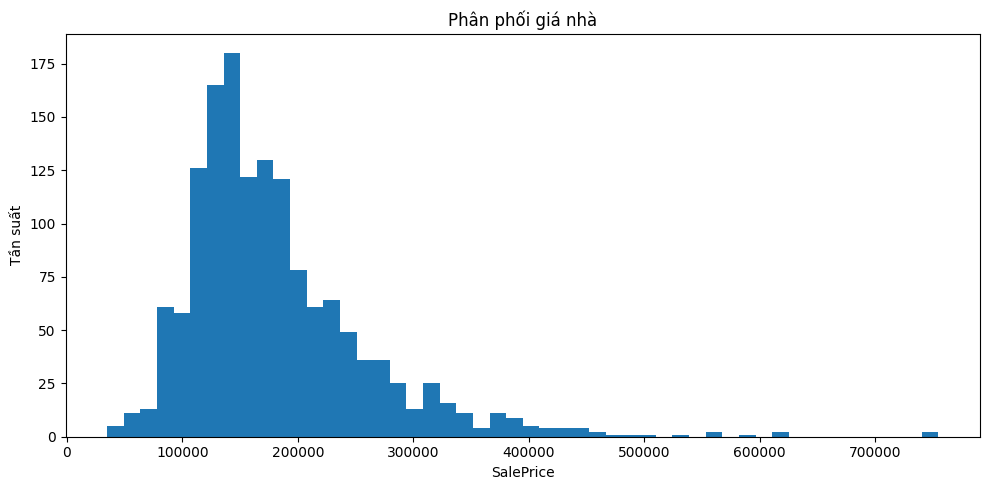

In [14]:
plt.figure(figsize=(10, 5))
plt.hist(df[target], bins=50)
plt.xlabel("SalePrice")
plt.ylabel("Tần suất")
plt.title("Phân phối giá nhà")
plt.tight_layout()
plt.show()

## 15. Biến đổi log cho SalePrice

`SalePrice` thường bị lệch phải mạnh. Ta dùng `log1p(SalePrice)` để giảm độ lệch và giúp các mô hình hồi quy học ổn định hơn.

Khi đánh giá, dự đoán sẽ được đưa ngược về thang giá ban đầu bằng `expm1()`.

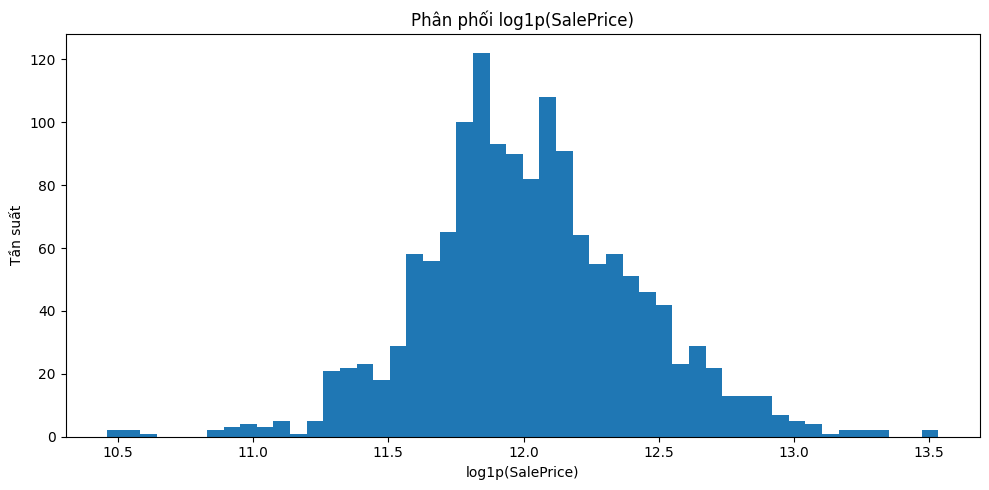

In [15]:
df["LogSalePrice"] = np.log1p(df[target])

plt.figure(figsize=(10, 5))
plt.hist(df["LogSalePrice"], bins=50)
plt.xlabel("log1p(SalePrice)")
plt.ylabel("Tần suất")
plt.title("Phân phối log1p(SalePrice)")
plt.tight_layout()
plt.show()

## 16. Kiểm tra độ lệch của biến mục tiêu

In [16]:
skew_original = df[target].skew()
skew_log = df["LogSalePrice"].skew()

print(f"Skewness SalePrice ban đầu: {skew_original:.4f}")
print(f"Skewness sau log1p: {skew_log:.4f}")

Skewness SalePrice ban đầu: 1.8829
Skewness sau log1p: 0.1213


## 17. Phân tích tương quan giữa biến số và SalePrice

Ta dùng ma trận tương quan cho các biến số để tìm các đặc trưng có quan hệ tuyến tính mạnh với giá nhà.

In [17]:
numeric_df = df.select_dtypes(include=np.number)

corr_with_target = numeric_df.corr()[target].drop(target).sort_values(key=np.abs, ascending=False)

display(corr_with_target.head(20).to_frame("Correlation"))

,Correlation
LogSalePrice,0.948374
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


## 18. Biểu đồ một số đặc trưng quan trọng

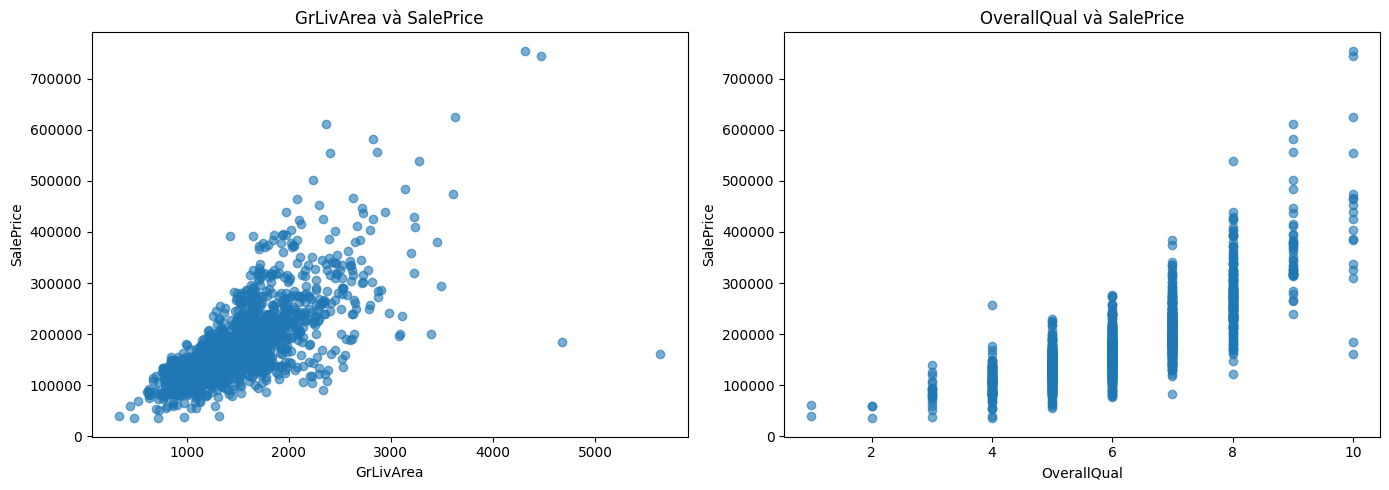

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df["GrLivArea"], df[target], alpha=0.6)
axes[0].set_xlabel("GrLivArea")
axes[0].set_ylabel("SalePrice")
axes[0].set_title("GrLivArea và SalePrice")

axes[1].scatter(df["OverallQual"], df[target], alpha=0.6)
axes[1].set_xlabel("OverallQual")
axes[1].set_ylabel("SalePrice")
axes[1].set_title("OverallQual và SalePrice")

plt.tight_layout()
plt.show()

## 19. Kiểm tra ngoại lệ ở GrLivArea

Không tự động xóa ngoại lệ vì mục tiêu của bài là đánh giá Feature Selection. Ta chỉ trực quan hóa để hiểu dữ liệu.

In [19]:
q1 = df["GrLivArea"].quantile(0.25)
q3 = df["GrLivArea"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

print(f"Q1 = {q1:.2f}")
print(f"Q3 = {q3:.2f}")
print(f"IQR = {iqr:.2f}")
print(f"Ngưỡng ngoại lệ phía trên = {upper:.2f}")
print("Số điểm vượt ngưỡng:", (df["GrLivArea"] > upper).sum())

Q1 = 1129.50
Q3 = 1776.75
IQR = 647.25
Ngưỡng ngoại lệ phía trên = 2747.62
Số điểm vượt ngưỡng: 31


## 20. Tạo tập đặc trưng X và biến mục tiêu y

- Loại bỏ `SalePrice` khỏi X vì đây là biến mục tiêu.
- Loại bỏ `Id` vì đây là mã định danh, không phải đặc trưng có ý nghĩa dự đoán.
- Dùng `log1p(SalePrice)` làm biến mục tiêu để huấn luyện.

In [20]:
X = df.drop(columns=[target, "LogSalePrice"], errors="ignore").copy()
X = X.drop(columns=["Id"], errors="ignore")

y = np.log1p(df[target].copy())

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1460, 79)
y shape: (1460,)


## 21. Chia dữ liệu Train/Test

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1168, 79)
X_test : (292, 79)
y_train: (1168,)
y_test : (292,)


## 22. Xác định nhóm biến số và biến phân loại

In [22]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Số biến số:", len(numeric_features))
print("Số biến phân loại:", len(categorical_features))

print("\nMột số biến số:", numeric_features[:15])
print("Một số biến phân loại:", categorical_features[:15])

Số biến số: 36
Số biến phân loại: 43

Một số biến số: ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF']
Một số biến phân loại: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl']


In [27]:
def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

## 24. Xây dựng quy trình tiền xử lý

### Biến số
- Điền thiếu bằng median.
- Chuẩn hóa bằng StandardScaler.

### Biến phân loại
- Điền thiếu bằng chuỗi `Missing`.
- Mã hóa One-Hot.

In [28]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", make_ohe())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Số đặc trưng trước Feature Selection:", X_train_processed.shape[1])
print("X_train_processed:", X_train_processed.shape)
print("X_test_processed :", X_test_processed.shape)

Số đặc trưng trước Feature Selection: 285
X_train_processed: (1168, 285)
X_test_processed : (292, 285)


## 25. Lấy tên các đặc trưng sau One-Hot Encoding

In [29]:
feature_names = preprocessor.get_feature_names_out()

print("Tổng số feature sau tiền xử lý:", len(feature_names))
print("\n20 feature đầu tiên:")
for name in feature_names[:20]:
    print("-", name)

Tổng số feature sau tiền xử lý: 285

20 feature đầu tiên:
- num__MSSubClass
- num__LotFrontage
- num__LotArea
- num__OverallQual
- num__OverallCond
- num__YearBuilt
- num__YearRemodAdd
- num__MasVnrArea
- num__BsmtFinSF1
- num__BsmtFinSF2
- num__BsmtUnfSF
- num__TotalBsmtSF
- num__1stFlrSF
- num__2ndFlrSF
- num__LowQualFinSF
- num__GrLivArea
- num__BsmtFullBath
- num__BsmtHalfBath
- num__FullBath
- num__HalfBath


## 26. Định nghĩa các mô hình cơ sở
- **SVM:** Support Vector Regression (SVR).
- **Random Forest:** RandomForestRegressor.
- **XGBoost:** XGBRegressor.

Tất cả mô hình được huấn luyện trên `log1p(SalePrice)`.

In [30]:
def create_models():
    return {
        "SVM": SVR(
            kernel="rbf",
            C=50,
            gamma="scale",
            epsilon=0.05
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "XGBoost": XGBRegressor(
            n_estimators=500,
            learning_rate=0.03,
            max_depth=4,
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            eval_metric="rmse",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    }

## 27. Hàm đánh giá mô hình

Các chỉ số:
- **MAE:** sai số tuyệt đối trung bình, càng thấp càng tốt.
- **RMSE:** phạt mạnh các sai số lớn, càng thấp càng tốt.
- **R²:** mức độ giải thích biến thiên của dữ liệu, càng cao càng tốt.
- **Time:** thời gian huấn luyện và dự đoán.

In [35]:
def evaluate_model(
    model_name,
    model,
    X_train_data,
    X_test_data,
    y_train_log,
    y_test_log,
    selection_name="No Feature Selection"
):
    start = time.time()

    model.fit(X_train_data, y_train_log)
    pred_log = model.predict(X_test_data)

    y_true = np.expm1(y_test_log)
    y_pred = np.maximum(0, np.expm1(pred_log))

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    elapsed = time.time() - start

    result = {
        "Feature Selection": selection_name,
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Time (s)": elapsed,
        "Num Features": X_train_data.shape[1]
    }

    return result, model, y_true, y_pred

## 28. Huấn luyện mô hình cơ sở trên toàn bộ feature

In [36]:
baseline_results = []
baseline_models = {}
baseline_predictions = {}

models = create_models()

for name, model in models.items():
    result, fitted_model, y_true, y_pred = evaluate_model(
        model_name=name,
        model=model,
        X_train_data=X_train_processed,
        X_test_data=X_test_processed,
        y_train_log=y_train,
        y_test_log=y_test,
        selection_name="No Feature Selection"
    )

    baseline_results.append(result)
    baseline_models[name] = fitted_model
    baseline_predictions[name] = (y_true, y_pred)

baseline_df = pd.DataFrame(baseline_results).sort_values("RMSE")
display(baseline_df)

,Feature Selection,Model,MAE,RMSE,R2,Time (s),Num Features
2,No Feature Selection,XGBoost,15377.943988,24959.262946,0.918782,0.768327,285
0,No Feature Selection,SVM,17282.322262,32689.781649,0.860681,0.220423,285
1,No Feature Selection,Random Forest,18424.519101,35061.304345,0.839734,0.843410,285


## 29. Nhận xét mô hình cơ sở
Mục tiêu của Feature Selection không chỉ là giảm số lượng biến mà còn hướng tới:
- Giảm nhiễu và dư thừa.
- Giảm chi phí tính toán.
- Giảm nguy cơ overfitting.
- Giữ hoặc cải thiện hiệu suất dự đoán.

# 30. FEATURE SELECTION 1 - SELECTKBEST

`SelectKBest` là một phương pháp Filter Method. Mỗi đặc trưng được chấm điểm độc lập với biến mục tiêu bằng `f_regression`, sau đó giữ lại K đặc trưng có điểm cao nhất.

In [37]:
K_BEST = min(100, X_train_processed.shape[1])

selector_kbest = SelectKBest(score_func=f_regression, k=K_BEST)

X_train_kbest = selector_kbest.fit_transform(X_train_processed, y_train)
X_test_kbest = selector_kbest.transform(X_test_processed)

selected_kbest_names = feature_names[selector_kbest.get_support()]

print("Số feature ban đầu:", X_train_processed.shape[1])
print("Số feature sau SelectKBest:", X_train_kbest.shape[1])

Số feature ban đầu: 285
Số feature sau SelectKBest: 100


## 31. Các feature được chọn bởi SelectKBest

In [38]:
kbest_scores = pd.DataFrame({
    "Feature": feature_names,
    "F_score": selector_kbest.scores_,
    "Selected": selector_kbest.get_support()
}).sort_values("F_score", ascending=False)

display(kbest_scores.head(30))

,Feature,F_score,Selected
3,num__OverallQual,2192.066010,True
15,num__GrLivArea,1053.840141,True
25,num__GarageCars,1027.680019,True
26,num__GarageArea,873.874814,True
11,num__TotalBsmtSF,646.429613,True
18,num__FullBath,602.704645,True
168,cat__ExterQual_TA,602.209513,True
12,num__1stFlrSF,594.000704,True
5,num__YearBuilt,581.109414,True
245,cat__GarageFinish_Unf,572.341970,True


## 32. Huấn luyện SVM, Random Forest và XGBoost với SelectKBest

In [39]:
kbest_results = []
kbest_models = {}
kbest_predictions = {}

for name, model in create_models().items():
    result, fitted_model, y_true, y_pred = evaluate_model(
        model_name=name,
        model=model,
        X_train_data=X_train_kbest,
        X_test_data=X_test_kbest,
        y_train_log=y_train,
        y_test_log=y_test,
        selection_name=f"SelectKBest (k={K_BEST})"
    )

    kbest_results.append(result)
    kbest_models[name] = fitted_model
    kbest_predictions[name] = (y_true, y_pred)

kbest_df = pd.DataFrame(kbest_results).sort_values("RMSE")
display(kbest_df)

,Feature Selection,Model,MAE,RMSE,R2,Time (s),Num Features
2,SelectKBest (k=100),XGBoost,16716.555731,25404.611196,0.915858,0.519545,100
0,SelectKBest (k=100),SVM,17964.768850,31493.416152,0.870692,0.147682,100
1,SelectKBest (k=100),Random Forest,18222.290158,33337.950339,0.855101,0.842651,100


# 33. FEATURE SELECTION 2 - SELECTFROMMODEL

`SelectFromModel` là phương pháp Embedded Method.

Ta dùng Random Forest để ước lượng độ quan trọng của từng feature và loại bỏ những feature có độ quan trọng thấp hơn ngưỡng trung vị (`median`).

In [40]:
selector_sfm = SelectFromModel(
    estimator=RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    threshold="median"
)

X_train_sfm = selector_sfm.fit_transform(X_train_processed, y_train)
X_test_sfm = selector_sfm.transform(X_test_processed)

selected_sfm_names = feature_names[selector_sfm.get_support()]

print("Số feature ban đầu:", X_train_processed.shape[1])
print("Số feature sau SelectFromModel:", X_train_sfm.shape[1])

Số feature ban đầu: 285
Số feature sau SelectFromModel: 143


## 34. Feature importance của mô hình dùng cho SelectFromModel

In [41]:
sfm_estimator = selector_sfm.estimator_

sfm_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": sfm_estimator.feature_importances_
}).sort_values("Importance", ascending=False)

display(sfm_importance.head(30))

,Feature,Importance
3,num__OverallQual,0.542380
15,num__GrLivArea,0.114800
11,num__TotalBsmtSF,0.043189
25,num__GarageCars,0.037220
26,num__GarageArea,0.026858
8,num__BsmtFinSF1,0.020810
12,num__1stFlrSF,0.019889
2,num__LotArea,0.014969
5,num__YearBuilt,0.014700
4,num__OverallCond,0.009659


## 35. Huấn luyện 3 mô hình với SelectFromModel

In [42]:
sfm_results = []
sfm_models = {}
sfm_predictions = {}

for name, model in create_models().items():
    result, fitted_model, y_true, y_pred = evaluate_model(
        model_name=name,
        model=model,
        X_train_data=X_train_sfm,
        X_test_data=X_test_sfm,
        y_train_log=y_train,
        y_test_log=y_test,
        selection_name="SelectFromModel - Random Forest"
    )

    sfm_results.append(result)
    sfm_models[name] = fitted_model
    sfm_predictions[name] = (y_true, y_pred)

sfm_df = pd.DataFrame(sfm_results).sort_values("RMSE")
display(sfm_df)

,Feature Selection,Model,MAE,RMSE,R2,Time (s),Num Features
2,SelectFromModel - Random Forest,XGBoost,15706.424403,25648.179823,0.914237,0.564989,143
1,SelectFromModel - Random Forest,Random Forest,18135.007429,33623.475494,0.852609,0.805194,143
0,SelectFromModel - Random Forest,SVM,17495.750503,33718.591875,0.851774,0.158933,143


# 36. FEATURE SELECTION 3 - RFE

`RFE` (Recursive Feature Elimination) là một Wrapper Method.

Quy trình:
1. Huấn luyện một mô hình có khả năng đánh giá tầm quan trọng của feature.
2. Loại bỏ một phần các feature kém quan trọng.
3. Lặp lại cho đến khi đạt số lượng feature mong muốn.

Ở đây dùng `LinearSVR` làm estimator và giữ lại khoảng 100 feature.

In [43]:
RFE_FEATURES = min(100, X_train_processed.shape[1])

rfe_estimator = LinearSVR(
    C=0.1,
    dual="auto",
    max_iter=10000,
    random_state=RANDOM_STATE
)

selector_rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=RFE_FEATURES,
    step=0.2
)

start_rfe = time.time()
X_train_rfe = selector_rfe.fit_transform(X_train_processed, y_train)
X_test_rfe = selector_rfe.transform(X_test_processed)
rfe_time = time.time() - start_rfe

selected_rfe_names = feature_names[selector_rfe.get_support()]

print("Số feature ban đầu:", X_train_processed.shape[1])
print("Số feature sau RFE:", X_train_rfe.shape[1])
print(f"Thời gian thực hiện RFE: {rfe_time:.2f} giây")

Số feature ban đầu: 285
Số feature sau RFE: 100
Thời gian thực hiện RFE: 0.58 giây


## 37. Các feature được chọn bởi RFE

In [44]:
rfe_ranking = pd.DataFrame({
    "Feature": feature_names,
    "Ranking": selector_rfe.ranking_,
    "Selected": selector_rfe.support_
}).sort_values(["Selected", "Ranking"], ascending=[False, True])

display(rfe_ranking.head(30))

,Feature,Ranking,Selected
15,num__GrLivArea,1,True
37,cat__MSZoning_FV,1,True
38,cat__MSZoning_RH,1,True
39,cat__MSZoning_RL,1,True
40,cat__MSZoning_RM,1,True
41,cat__Street_Grvl,1,True
42,cat__Street_Pave,1,True
43,cat__Alley_Grvl,1,True
44,cat__Alley_Pave,1,True
45,cat__LotShape_IR1,1,True


## 38. Huấn luyện 3 mô hình với RFE

In [45]:
rfe_results = []
rfe_models = {}
rfe_predictions = {}

for name, model in create_models().items():
    result, fitted_model, y_true, y_pred = evaluate_model(
        model_name=name,
        model=model,
        X_train_data=X_train_rfe,
        X_test_data=X_test_rfe,
        y_train_log=y_train,
        y_test_log=y_test,
        selection_name=f"RFE (n={RFE_FEATURES})"
    )

    rfe_results.append(result)
    rfe_models[name] = fitted_model
    rfe_predictions[name] = (y_true, y_pred)

rfe_df = pd.DataFrame(rfe_results).sort_values("RMSE")
display(rfe_df)

,Feature Selection,Model,MAE,RMSE,R2,Time (s),Num Features
2,RFE (n=100),XGBoost,21768.852539,33287.900602,0.855536,0.268314,100
1,RFE (n=100),Random Forest,24343.469892,42312.836809,0.766584,0.809395,100
0,RFE (n=100),SVM,28832.034600,45470.242932,0.730449,0.413564,100


# 39. Tổng hợp toàn bộ kết quả

Ta gom kết quả của:
- Không Feature Selection.
- SelectKBest.
- SelectFromModel.
- RFE.

Sau đó so sánh theo MAE, RMSE, R² và số lượng feature.

In [46]:
all_results = pd.concat(
    [baseline_df, kbest_df, sfm_df, rfe_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    by=["RMSE", "MAE"],
    ascending=[True, True]
).reset_index(drop=True)

display(all_results)

,Feature Selection,Model,MAE,RMSE,R2,Time (s),Num Features
0,No Feature Selection,XGBoost,15377.943988,24959.262946,0.918782,0.768327,285
1,SelectKBest (k=100),XGBoost,16716.555731,25404.611196,0.915858,0.519545,100
2,SelectFromModel - Random Forest,XGBoost,15706.424403,25648.179823,0.914237,0.564989,143
3,SelectKBest (k=100),SVM,17964.768850,31493.416152,0.870692,0.147682,100
4,No Feature Selection,SVM,17282.322262,32689.781649,0.860681,0.220423,285
5,RFE (n=100),XGBoost,21768.852539,33287.900602,0.855536,0.268314,100
6,SelectKBest (k=100),Random Forest,18222.290158,33337.950339,0.855101,0.842651,100
7,SelectFromModel - Random Forest,Random Forest,18135.007429,33623.475494,0.852609,0.805194,143
8,SelectFromModel - Random Forest,SVM,17495.750503,33718.591875,0.851774,0.158933,143
9,No Feature Selection,Random Forest,18424.519101,35061.304345,0.839734,0.843410,285


## 40. Xếp hạng kết quả theo RMSE

In [47]:
ranking_rmse = all_results[[
    "Feature Selection", "Model", "Num Features", "MAE", "RMSE", "R2", "Time (s)"
]].sort_values("RMSE")

display(ranking_rmse)

,Feature Selection,Model,Num Features,MAE,RMSE,R2,Time (s)
0,No Feature Selection,XGBoost,285,15377.943988,24959.262946,0.918782,0.768327
1,SelectKBest (k=100),XGBoost,100,16716.555731,25404.611196,0.915858,0.519545
2,SelectFromModel - Random Forest,XGBoost,143,15706.424403,25648.179823,0.914237,0.564989
3,SelectKBest (k=100),SVM,100,17964.768850,31493.416152,0.870692,0.147682
4,No Feature Selection,SVM,285,17282.322262,32689.781649,0.860681,0.220423
5,RFE (n=100),XGBoost,100,21768.852539,33287.900602,0.855536,0.268314
6,SelectKBest (k=100),Random Forest,100,18222.290158,33337.950339,0.855101,0.842651
7,SelectFromModel - Random Forest,Random Forest,143,18135.007429,33623.475494,0.852609,0.805194
8,SelectFromModel - Random Forest,SVM,143,17495.750503,33718.591875,0.851774,0.158933
9,No Feature Selection,Random Forest,285,18424.519101,35061.304345,0.839734,0.843410


## 41. So sánh RMSE giữa các phương pháp Feature Selection

Feature Selection,No Feature Selection,RFE (n=100),SelectFromModel - Random Forest,SelectKBest (k=100)
Model,,,,
Random Forest,35061.304345,42312.836809,33623.475494,33337.950339
SVM,32689.781649,45470.242932,33718.591875,31493.416152
XGBoost,24959.262946,33287.900602,25648.179823,25404.611196


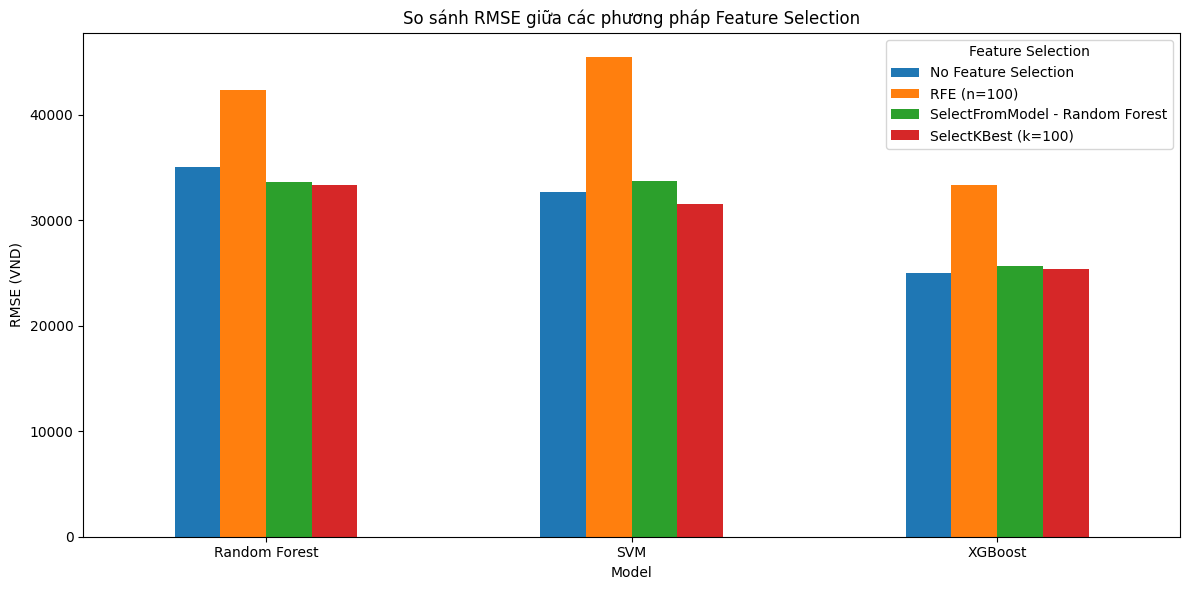

In [48]:
rmse_pivot = all_results.pivot_table(
    index="Model",
    columns="Feature Selection",
    values="RMSE",
    aggfunc="mean"
)

display(rmse_pivot)

rmse_pivot.plot(kind="bar", figsize=(12, 6))
plt.ylabel("RMSE (VND)")
plt.title("So sánh RMSE giữa các phương pháp Feature Selection")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 42. So sánh R² giữa các phương pháp Feature Selection

Feature Selection,No Feature Selection,RFE (n=100),SelectFromModel - Random Forest,SelectKBest (k=100)
Model,,,,
Random Forest,0.839734,0.766584,0.852609,0.855101
SVM,0.860681,0.730449,0.851774,0.870692
XGBoost,0.918782,0.855536,0.914237,0.915858


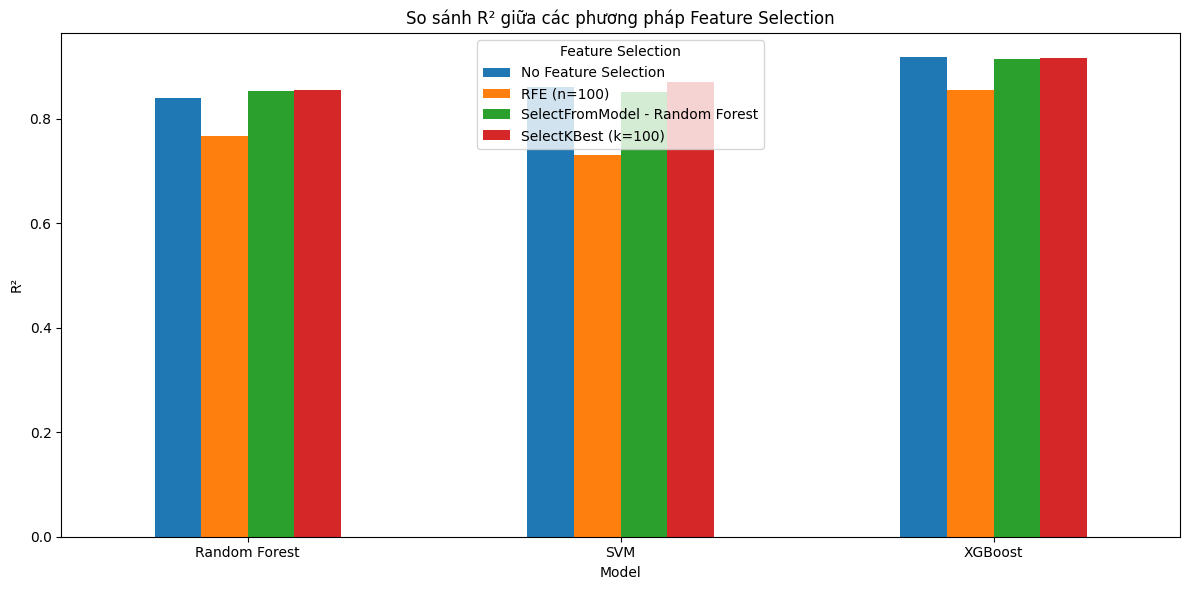

In [49]:
r2_pivot = all_results.pivot_table(
    index="Model",
    columns="Feature Selection",
    values="R2",
    aggfunc="mean"
)

display(r2_pivot)

r2_pivot.plot(kind="bar", figsize=(12, 6))
plt.ylabel("R²")
plt.title("So sánh R² giữa các phương pháp Feature Selection")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 43. So sánh số lượng feature

,Feature Selection,Num Features
0,No Feature Selection,285
1,SelectKBest (k=100),100
2,SelectFromModel - Random Forest,143
5,RFE (n=100),100


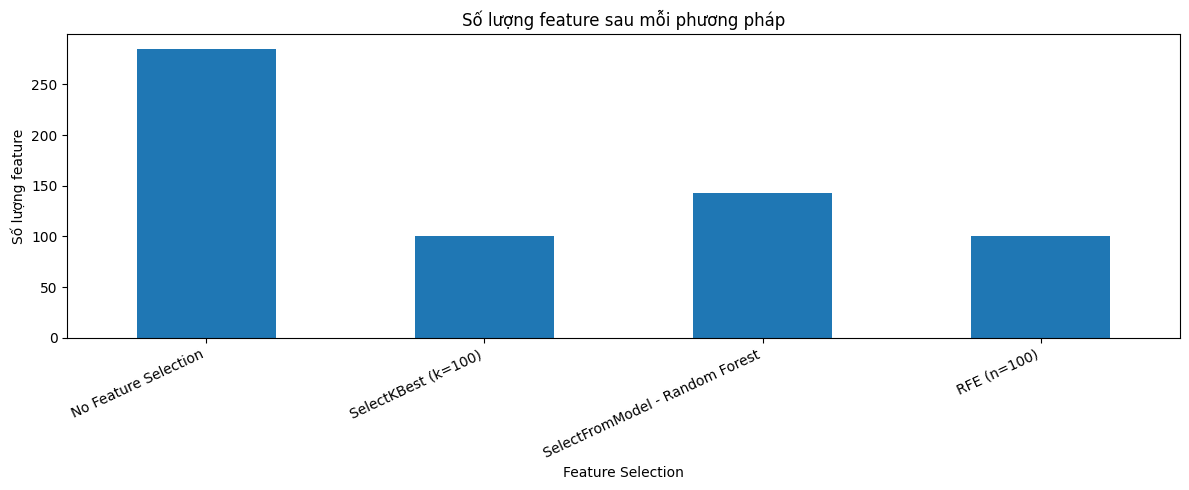

In [50]:
feature_count_df = all_results[[
    "Feature Selection", "Num Features"
]].drop_duplicates()

display(feature_count_df)

feature_count_df.plot(
    x="Feature Selection",
    y="Num Features",
    kind="bar",
    legend=False,
    figsize=(12, 5)
)
plt.ylabel("Số lượng feature")
plt.title("Số lượng feature sau mỗi phương pháp")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 44. Xác định kết quả tốt nhất

Tiêu chí chính là RMSE thấp nhất. Trong trường hợp hai kết quả gần nhau, có thể ưu tiên mô hình có ít feature hơn hoặc thời gian chạy thấp hơn.

In [51]:
best_row = all_results.iloc[0]

print("KẾT QUẢ TỐT NHẤT")
print("Feature Selection:", best_row["Feature Selection"])
print("Model:", best_row["Model"])
print("Số feature:", int(best_row["Num Features"]))
print(f"MAE:  {best_row['MAE']:,.2f}")
print(f"RMSE: {best_row['RMSE']:,.2f}")
print(f"R²:   {best_row['R2']:.4f}")
print(f"Time: {best_row['Time (s)']:.2f} s")

KẾT QUẢ TỐT NHẤT
Feature Selection: No Feature Selection
Model: XGBoost
Số feature: 285
MAE:  15,377.94
RMSE: 24,959.26
R²:   0.9188
Time: 0.77 s


## 45. So sánh mô hình trước và sau Feature Selection

Một phương pháp Feature Selection được xem là hiệu quả khi:
- Số feature giảm đáng kể.
- RMSE/MAE không tăng quá nhiều hoặc giảm.
- R² được giữ ổn định hoặc tăng.
- Thời gian huấn luyện giảm hoặc vẫn chấp nhận được.

In [53]:
summary_compare = all_results.copy()
summary_compare["RMSE_%_vs_Baseline_BestModel"] = np.nan

for model_name in all_results["Model"].unique():
    baseline_rmse = all_results[
        (all_results["Model"] == model_name) &
        (all_results["Feature Selection"] == "No Feature Selection")
    ]["RMSE"].iloc[0]

    idx = summary_compare["Model"] == model_name
    summary_compare.loc[idx, "RMSE_%_vs_Baseline_BestModel"] = (
        (summary_compare.loc[idx, "RMSE"] - baseline_rmse)
        / baseline_rmse * 100
    )

display(summary_compare.sort_values(["Model", "RMSE"]))

,Feature Selection,Model,MAE,RMSE,R2,Time (s),Num Features,RMSE_%_vs_Baseline_BestModel
6,SelectKBest (k=100),Random Forest,18222.290158,33337.950339,0.855101,0.842651,100,-4.915259
7,SelectFromModel - Random Forest,Random Forest,18135.007429,33623.475494,0.852609,0.805194,143,-4.100899
9,No Feature Selection,Random Forest,18424.519101,35061.304345,0.839734,0.843410,285,0.000000
10,RFE (n=100),Random Forest,24343.469892,42312.836809,0.766584,0.809395,100,20.682438
3,SelectKBest (k=100),SVM,17964.768850,31493.416152,0.870692,0.147682,100,-3.659754
4,No Feature Selection,SVM,17282.322262,32689.781649,0.860681,0.220423,285,0.000000
8,SelectFromModel - Random Forest,SVM,17495.750503,33718.591875,0.851774,0.158933,143,3.147192
11,RFE (n=100),SVM,28832.034600,45470.242932,0.730449,0.413564,100,39.096197
0,No Feature Selection,XGBoost,15377.943988,24959.262946,0.918782,0.768327,285,0.000000
1,SelectKBest (k=100),XGBoost,16716.555731,25404.611196,0.915858,0.519545,100,1.784300


# 46. Trực quan hóa Actual vs Predicted của mô hình tốt nhất

Biểu đồ càng gần đường chéo `y = x` thì dự đoán càng tốt.

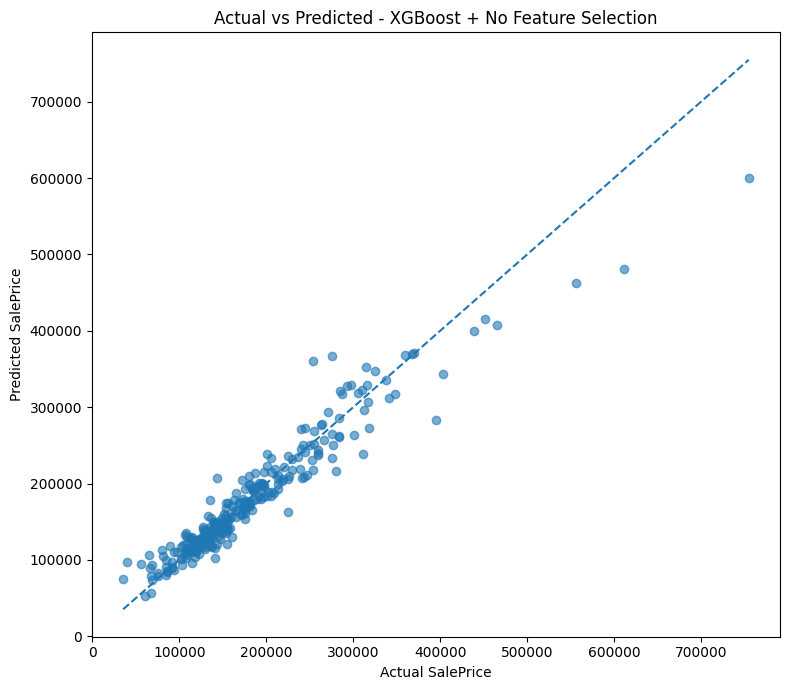

In [54]:
prediction_store = {}

prediction_store.update({
    ("No Feature Selection", name): value
    for name, value in baseline_predictions.items()
})
prediction_store.update({
    ("SelectKBest", name): value
    for name, value in kbest_predictions.items()
})
prediction_store.update({
    ("SelectFromModel - Random Forest", name): value
    for name, value in sfm_predictions.items()
})
prediction_store.update({
    ("RFE", name): value
    for name, value in rfe_predictions.items()
})

best_selection_full = best_row["Feature Selection"]
best_model_name = best_row["Model"]

if best_selection_full == "No Feature Selection":
    sel_key = "No Feature Selection"
elif best_selection_full.startswith("SelectKBest"):
    sel_key = "SelectKBest"
elif best_selection_full.startswith("SelectFromModel"):
    sel_key = "SelectFromModel - Random Forest"
else:
    sel_key = "RFE"

y_true_best, y_pred_best = prediction_store[(sel_key, best_model_name)]

plt.figure(figsize=(8, 7))
plt.scatter(y_true_best, y_pred_best, alpha=0.6)

line_min = min(y_true_best.min(), y_pred_best.min())
line_max = max(y_true_best.max(), y_pred_best.max())
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title(f"Actual vs Predicted - {best_model_name} + {best_selection_full}")
plt.tight_layout()
plt.show()

## 47. Phân tích phần dư

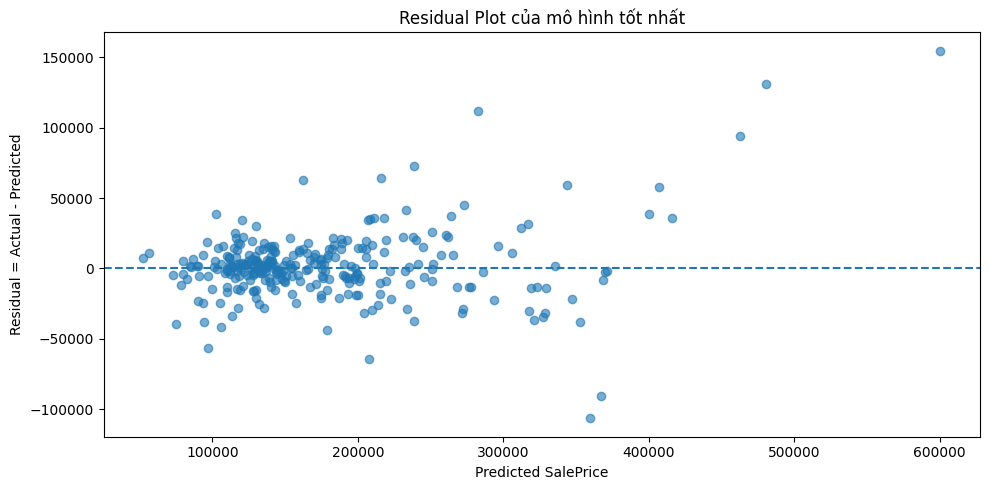

In [55]:
residuals = y_true_best - y_pred_best

plt.figure(figsize=(10, 5))
plt.scatter(y_pred_best, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted SalePrice")
plt.ylabel("Residual = Actual - Predicted")
plt.title("Residual Plot của mô hình tốt nhất")
plt.tight_layout()
plt.show()

## 48. Feature importance / Permutation Importance

Permutation Importance không phụ thuộc trực tiếp vào loại mô hình. Ta dùng nó để xem các feature còn lại ảnh hưởng như thế nào đến mô hình tốt nhất.

In [57]:
if sel_key == "No Feature Selection":
    X_test_best = X_test_processed
    selected_feature_names_best = feature_names
    best_fitted_model = baseline_models[best_model_name]
elif sel_key == "SelectKBest":
    X_test_best = X_test_kbest
    selected_feature_names_best = selected_kbest_names
    best_fitted_model = kbest_models[best_model_name]
elif sel_key == "SelectFromModel - Random Forest":
    X_test_best = X_test_sfm
    selected_feature_names_best = selected_sfm_names
    best_fitted_model = sfm_models[best_model_name]
else:
    X_test_best = X_test_rfe
    selected_feature_names_best = selected_rfe_names
    best_fitted_model = rfe_models[best_model_name]

perm = permutation_importance(
    best_fitted_model,
    X_test_best,
    y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    scoring="neg_root_mean_squared_error"
)

perm_df = pd.DataFrame({
    "Feature": selected_feature_names_best,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(perm_df.head(20))

,Feature,Importance_Mean,Importance_Std
3,num__OverallQual,0.079676,0.002838
15,num__GrLivArea,0.077231,0.003743
11,num__TotalBsmtSF,0.015145,0.001138
4,num__OverallCond,0.010349,0.001101
8,num__BsmtFinSF1,0.008997,0.001338
5,num__YearBuilt,0.008537,0.001522
2,num__LotArea,0.007339,0.000568
6,num__YearRemodAdd,0.007161,0.002029
12,num__1stFlrSF,0.005664,0.001418
25,num__GarageCars,0.005352,0.000774


## 49. Biểu đồ Top 20 feature quan trọng nhất

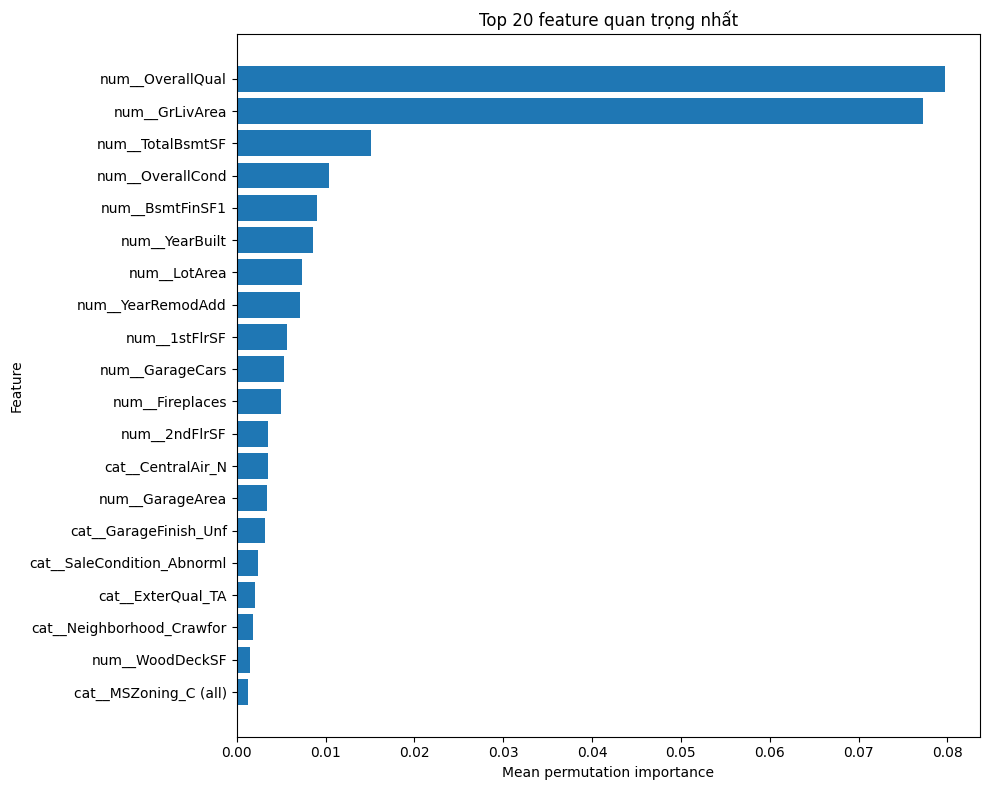

In [58]:
top_perm = perm_df.head(20).sort_values("Importance_Mean")

plt.figure(figsize=(10, 8))
plt.barh(top_perm["Feature"], top_perm["Importance_Mean"])
plt.xlabel("Mean permutation importance")
plt.ylabel("Feature")
plt.title("Top 20 feature quan trọng nhất")
plt.tight_layout()
plt.show()

## 51. Xuất kết quả ra file CSV

In [61]:
all_results.to_csv(
    "feature_selection_results.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame({"Feature": selected_kbest_names}).to_csv(
    "selected_features_kbest.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame({"Feature": selected_sfm_names}).to_csv(
    "selected_features_sfm.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame({"Feature": selected_rfe_names}).to_csv(
    "selected_features_rfe.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất các file CSV kết quả.")

Đã xuất các file CSV kết quả.


# 52. Kết luận

### Các nội dung đã thực hiện
- Đọc và kiểm tra bộ dữ liệu House Prices.
- Phân tích dữ liệu thiếu, dữ liệu số và biến phân loại.
- Trực quan hóa phân phối `SalePrice` và một số quan hệ quan trọng.
- Tiền xử lý bằng Imputation + One-Hot Encoding + StandardScaler.
- Xây dựng baseline với:
  - SVM
  - Random Forest
  - XGBoost
- Áp dụng 3 nhóm Feature Selection:
  - **SelectKBest:** Filter Method.
  - **SelectFromModel:** Embedded Method.
  - **RFE:** Wrapper Method.
- Đánh giá bằng MAE, RMSE, R² và thời gian chạy.
- Xác định mô hình/Feature Selection tốt nhất.
- Phân tích Actual vs Predicted, Residual và Permutation Importance.
- Xuất kết quả ra các file CSV.